# **Import Requirements**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Import Dataset

In [3]:
df = pd.read_csv("/content/drive/MyDrive/Credit Card Segmentation/Dataset/Processed/credit_card_clean.csv")

In [4]:
df.sample(8)

,cust_id,balance,balance_frequency,purchases,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments,prc_full_payment,tenure
3036,C13125,3821.413393,1.000000,197.00,80.50,116.50,3926.684678,0.833333,0.083333,0.750000,0.333333,11,11,7000.0,700.151706,1540.518189,0.000000,12
645,C10671,1482.235539,1.000000,14604.87,2475.93,12128.94,0.000000,1.000000,0.583333,1.000000,0.000000,0,219,15500.0,14462.630560,340.717801,1.000000,12
2531,C12605,4424.767314,0.833333,0.00,0.00,0.00,7013.528326,0.000000,0.000000,0.000000,0.666667,13,0,7000.0,864.141100,983.378772,0.000000,6
3379,C13475,4005.202539,1.000000,1425.23,1208.45,216.78,2637.011333,1.000000,1.000000,0.416667,0.333333,6,46,5550.0,1607.054463,1061.281539,0.000000,12
5662,C15820,3842.454902,1.000000,0.00,0.00,0.00,6381.534619,0.000000,0.000000,0.000000,0.500000,24,0,6500.0,3869.748950,1742.491124,0.083333,12
7564,C17769,5.170635,0.545455,367.95,0.00,367.95,0.000000,0.916667,0.000000,0.916667,0.000000,0,11,1000.0,400.457139,28.883262,0.125000,12
2876,C12960,512.058666,0.818182,921.20,664.73,256.47,0.000000,0.416667,0.166667,0.250000,0.000000,0,7,5500.0,1851.553319,786.588160,0.000000,12
3165,C13255,7293.108794,1.000000,0.00,0.00,0.00,1877.531533,0.000000,0.000000,0.000000,0.333333,4,0,8500.0,1816.195475,1659.404676,0.000000,12


# **EDA Bivariate**

## **Apakah customer dengan credit limit lebih tinggi cenderung memiliki balance yang lebih tinggi?**

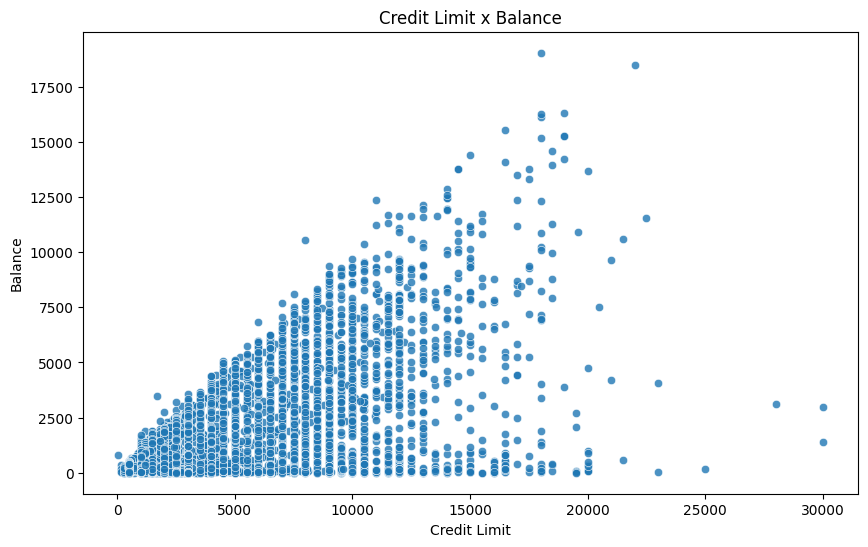


Korelasi : 0.531


In [5]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="credit_limit",
    y="balance",
    alpha = 0.8
)
# sns.regplot(
#     data=df,
#     x="balance",
#     y="credit_limit",
#     scatter_kws = {"alpha": 0.2}
# )

plt.title("Credit Limit x Balance")
plt.xlabel("Credit Limit")
plt.ylabel("Balance")
plt.show()
corr = df["credit_limit"].corr(df["balance"])
print()
print(f"Korelasi : {corr:.3f}")

In [6]:
df['credit_utilization'] = df['balance']/df['credit_limit']

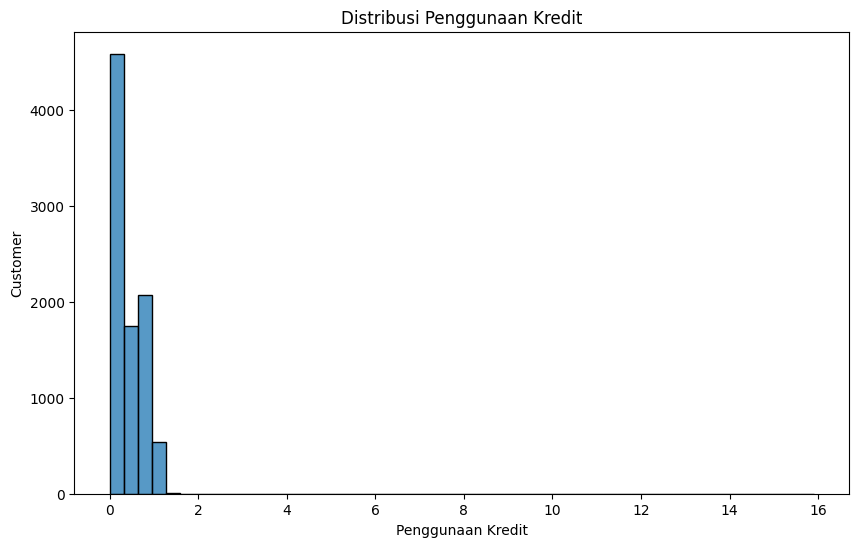

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='credit_utilization',
    bins=50
)

plt.title('Distribusi Penggunaan Kredit')
plt.xlabel('Penggunaan Kredit')
plt.ylabel('Customer')
plt.show()

In [8]:
df['credit_utilization'] = (
    df['balance'] / df['credit_limit']

)
df['credit_utilization'].describe()

,credit_utilization
count,8950.000000
mean,0.388884
std,0.389722
min,0.000000
25%,0.041494
50%,0.302720
75%,0.717571
max,15.909951


In [9]:
df['credit_utilization'].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00])

,credit_utilization
0.25,0.041494
0.50,0.302720
0.75,0.717571
0.90,0.919888
0.95,0.966686
0.99,1.057059
1.00,15.909951


In [10]:
print("credit_utilization > 1 = ",len(df[df['credit_utilization']>1] ))

credit_utilization > 1 =  227


In [11]:
(df['credit_utilization'] > 1).mean() * 100

np.float64(2.536312849162011)

In [12]:
df.loc[
    df['credit_utilization'] > 1,
    ['balance', 'credit_limit', 'credit_utilization']
].sort_values('credit_utilization', ascending=False).sample(10)

,balance,credit_limit,credit_utilization
3568,1330.716005,1300.0,1.023628
3697,1092.570471,1000.0,1.092570
6879,1256.460026,1200.0,1.047050
7416,1273.498021,1200.0,1.061248
5746,1821.024103,1800.0,1.011680
6069,1066.830615,1000.0,1.066831
562,1029.101022,1000.0,1.029101
6369,1316.179352,1200.0,1.096816
8492,1047.182049,1000.0,1.047182
5432,1597.679284,1550.0,1.030761


In [13]:
df.loc[
    df['credit_utilization'] > 1,
    ['balance','credit_limit','credit_utilization']
].describe()

,balance,credit_limit,credit_utilization
count,227.000000,227.000000,227.000000
mean,2252.972135,2099.779736,1.150643
std,2224.762263,2093.376078,0.994770
min,151.704474,50.000000,1.000363
25%,1191.257796,1000.000000,1.014765
50%,1520.956418,1400.000000,1.042021
75%,2331.562106,2100.000000,1.090208
max,19043.138560,18000.000000,15.909951


## **Apakah customer dengan balance tinggi cenderung memiliki payment yang  tinggi?**

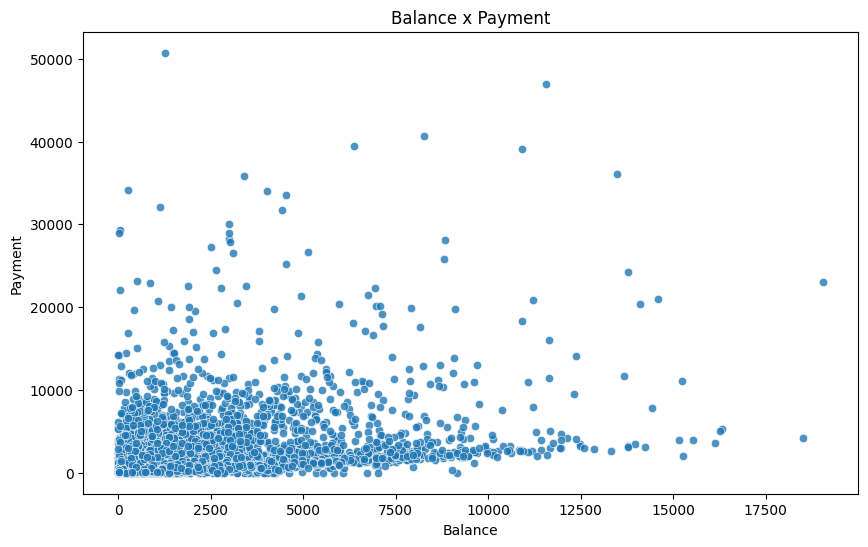


Korelasi = 0.323


In [14]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='balance',
    y='payments',
    alpha = 0.8
)

plt.title('Balance x Payment')
plt.xlabel('Balance')
plt.ylabel('Payment')
plt.show()
corr = df['balance'].corr(df['payments'])
print()
print(f'Korelasi = {corr:.3f}')

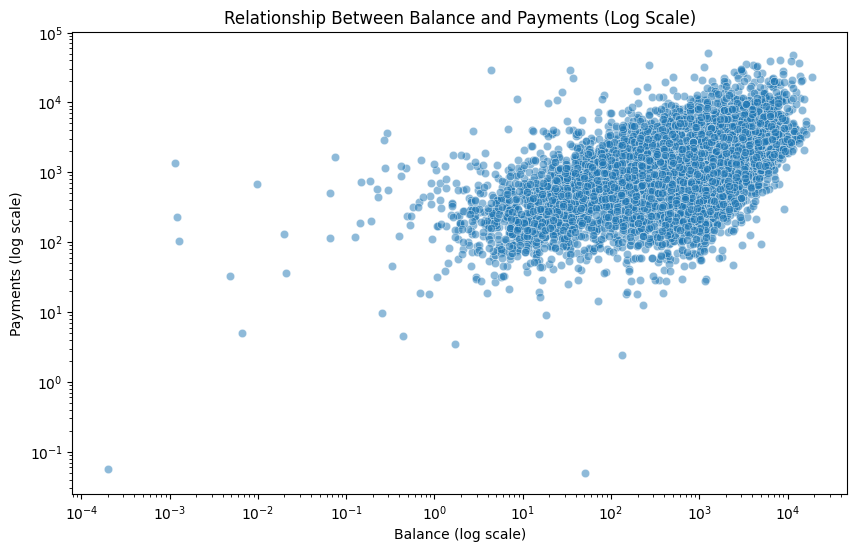

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='balance',
    y='payments',
    alpha=0.5
)

plt.xscale('log')
plt.yscale('log')

plt.title('Relationship Between Balance and Payments (Log Scale)')
plt.xlabel('Balance (log scale)')
plt.ylabel('Payments (log scale)')
plt.show()

## **Berapa besar customer membayar dibandingkan dengan minimumnya**

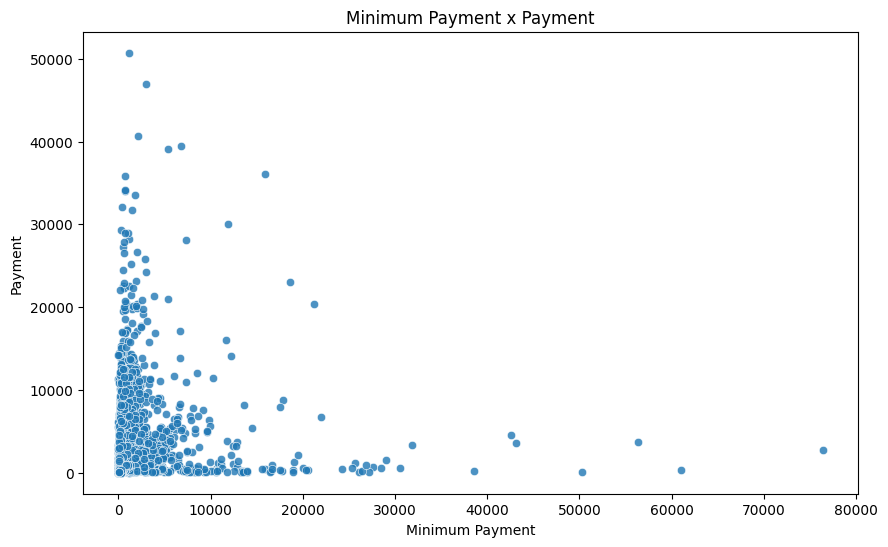


Korelasi = 0.129


In [16]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='minimum_payments',
    y='payments',
    alpha = 0.8
)

plt.title('Minimum Payment x Payment')
plt.xlabel('Minimum Payment')
plt.ylabel('Payment')
plt.show()
corr = df['minimum_payments'].corr(df['payments'])
print()
print(f'Korelasi = {corr:.3f}')

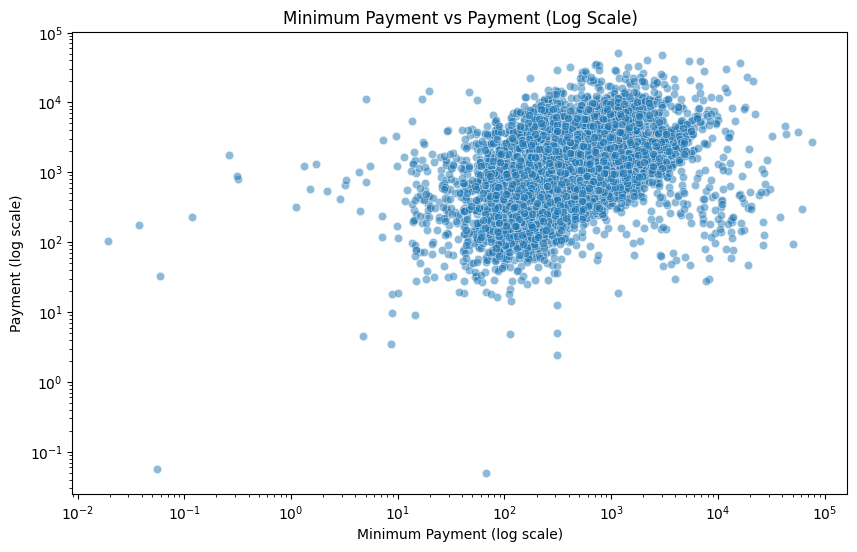

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='minimum_payments',
    y='payments',
    alpha=0.5
)

plt.xscale('log')
plt.yscale('log')

plt.title('Minimum Payment vs Payment (Log Scale)')
plt.xlabel('Minimum Payment (log scale)')
plt.ylabel('Payment (log scale)')
plt.show()

## **Customer yang membayar lebih besar juga cenderung melunasi tagihan secara penuh?**

In [18]:
df['prc_full_payment'].describe()

,prc_full_payment
count,8950.000000
mean,0.153715
std,0.292499
min,0.000000
25%,0.000000
50%,0.000000
75%,0.142857
max,1.000000


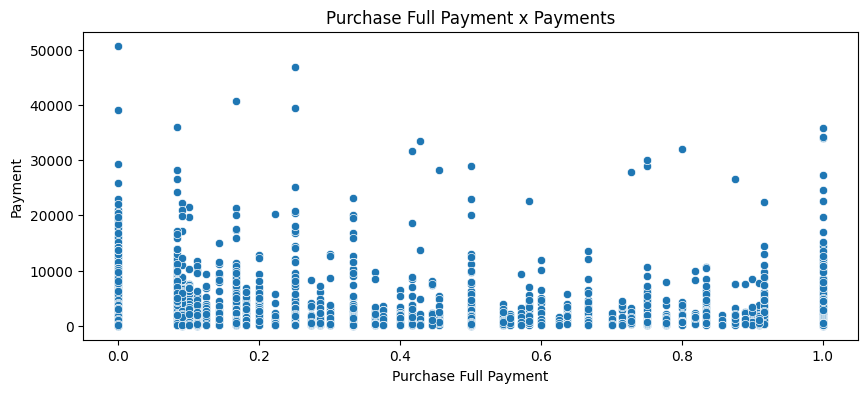


Korelasi = 0.112


In [19]:
plt.figure(figsize=(10,4))

sns.scatterplot(
    data=df,
    x='prc_full_payment',
    y='payments'
)

plt.title('Purchase Full Payment x Payments')
plt.xlabel('Purchase Full Payment')
plt.ylabel('Payment')
plt.show()
corr = df['payments'].corr(df['prc_full_payment'])
print()
print(f'Korelasi = {corr:.3f}')

## **Customer lebih banyak berbelanja juga melakukan pembayaran lebih besar?**

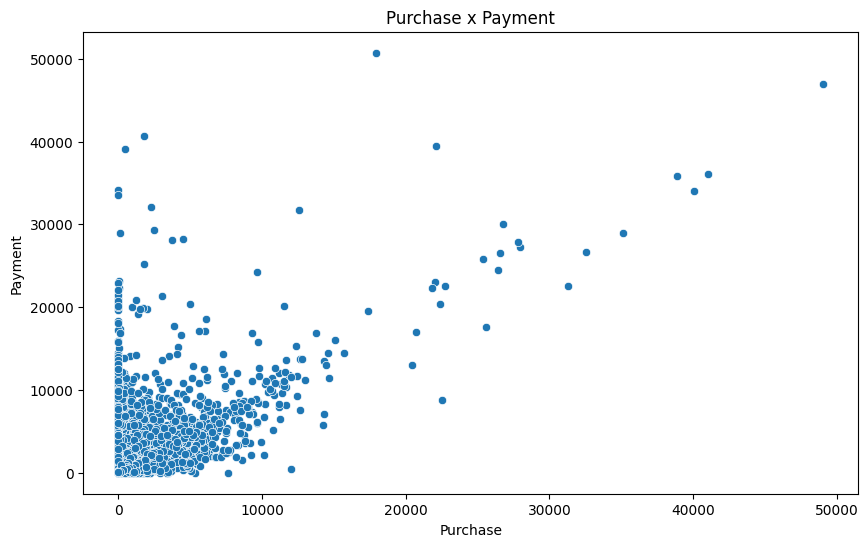


Korelasi = 0.603


In [20]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data = df,
    x = 'purchases',
    y= 'payments'
)

plt.title('Purchase x Payment')
plt.xlabel('Purchase')
plt.ylabel('Payment')
plt.show()
corr = df['purchases'].corr(df['payments'])
print()
print(f'Korelasi = {corr:.3f}')

## **Apakah Customer yang lebih sering purchase, nominal purchasenya lebih tinggi juga?**

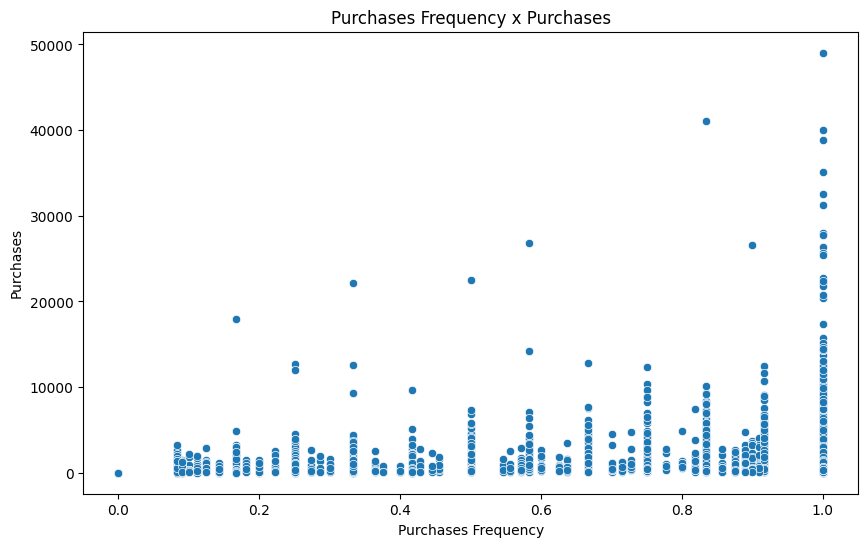


Korelasi = 0.393


In [21]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data = df,
    x = 'purchases_frequency',
    y= 'purchases'
)

plt.title('Purchases Frequency x Purchases')
plt.xlabel('Purchases Frequency')
plt.ylabel('Purchases')
plt.show()
corr = df['purchases_frequency'].corr(df['purchases'])
print()
print(f'Korelasi = {corr:.3f}')

## **Apakah customer yang sering cash advance juga cenderung memiliki total cash advance yang lebih besar?**

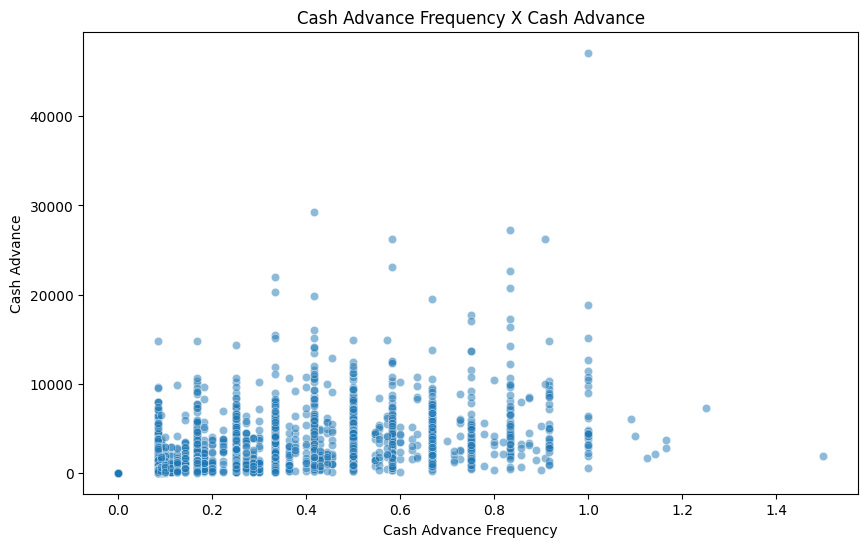


Korelasi = 0.629


In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='cash_advance_frequency',
    y='cash_advance',
    alpha=0.5
)

plt.title('Cash Advance Frequency X Cash Advance')
plt.xlabel('Cash Advance Frequency')
plt.ylabel('Cash Advance')
plt.show()
corr = df['cash_advance_frequency'].corr(df['cash_advance'])
print()
print(f'Korelasi = {corr:.3f}')

## **Customer yang banyak menggunakan cash advance, apakah juga melakukan pembayaran yang besar?**

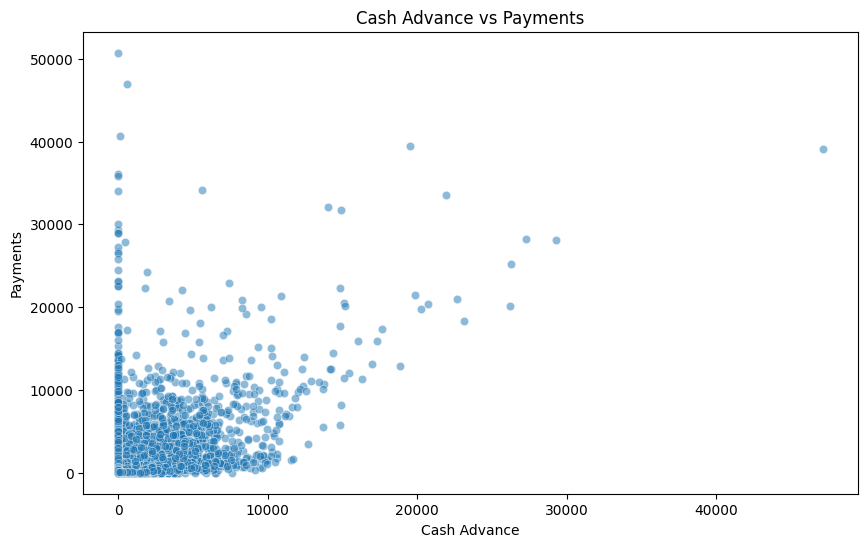


Korelasi = 0.453


In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='cash_advance',
    y='payments',
    alpha=0.5
)

plt.title('Cash Advance vs Payments')
plt.xlabel('Cash Advance')
plt.ylabel('Payments')
plt.show()
corr = df['cash_advance'].corr(df['payments'])
print()
print(f'Korelasi = {corr:.3f}')

Terlihat bahwa sebagian besar customer memiliki cash advance dan payments yang rendah. Hubungan positif antar 2 variabel tidak kuat, namun beberapa customer memiliki cash advance tinggi diikuti dengan payment yang tinggi

##